# Hyper-Kvasir: labelled videos
How much video do we have, and where? Total / mean length per organ, category and finding.

Durations come from `video_meta.py` (ffprobe over `out/labeled-videos`, cached in `video-metadata.csv`).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', context='notebook', palette='deep', font_scale=1.05)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

In [2]:
meta = pd.read_csv('./video-metadata.csv')
labels = pd.read_csv('./out/labeled-videos/video-labels.csv').rename(columns={
    'Video file': 'id', 'Organ': 'organ', 'Finding 1': 'finding', 'Classification 1': 'category',
    'Detailed description of finding': 'detail', 'Finding 2': 'finding2', 'Classification 2': 'category2'})
df = meta.merge(labels, on='id', how='left', validate='1:1', suffixes=('_dir', ''))
df['finding'] = df.finding.str.strip().str.lower()
df['minutes'] = df.duration_s / 60
print(len(df), 'videos,', df.organ.isna().sum(), 'without a label row')
df.head()

374 videos, 0 without a label row


,id,tract,category_dir,folder,duration_s,size_mb,fps,frames,width,height,codec,organ,finding,category,detail,finding2,category2,minutes
0,164c76bd-cf72-46f6-a643-ddfecb6448d7,lower-gi-tract,anatomical-landmarks,cecum,31.080000,26.159104,25.000000,777,720,576,vc1,Lower GI,cecum,Anatomical landmarks,NaN,ileocecal valve,Anatomical landmarks,0.518000
1,44c8c58b-e226-4f10-adf4-b8f91b71c476,lower-gi-tract,anatomical-landmarks,cecum,3.840000,2.856448,25.000000,96,720,576,vc1,Lower GI,cecum,Anatomical landmarks,NaN,NaN,NaN,0.064000
2,6ab427b7-ba71-442c-be78-0f5a97f3f6eb,lower-gi-tract,anatomical-landmarks,cecum,32.440000,22.921728,25.000000,811,720,576,vc1,Lower GI,cecum,Anatomical landmarks,NaN,polyp,Pathological findings,0.540667
3,bd3787db-19c6-41f0-a28e-08b6360ce104,lower-gi-tract,anatomical-landmarks,cecum,78.400000,56.322560,25.000000,1960,720,576,vc1,Lower GI,cecum,Anatomical landmarks,NaN,BBPS 2-3,Quality of mucosal views,1.306667
4,226ad7b7-00bd-4679-8a7a-bc7c07f0dc51,lower-gi-tract,pathological-findings,anastomotic-leakage,22.916276,35.528192,25.004063,573,1280,1024,vc1,Lower GI,cavity of anastomotic leak,Pathological findings,NaN,NaN,NaN,0.381938


## Overview

In [3]:
tot = df.duration_s.sum()
print(f'Total length: {tot/3600:.2f} h ({tot/60:,.0f} min), {df.frames.sum():,} frames, {df.size_mb.sum()/1e3:.1f} GB')
print(df.duration_s.describe().round(1).to_string())

Total length: 9.68 h (581 min), 875,940 frames, 32.5 GB
count    374.0
mean      93.1
std      111.2
min        1.4
25%       31.1
50%       62.6
75%      120.2
max      602.2


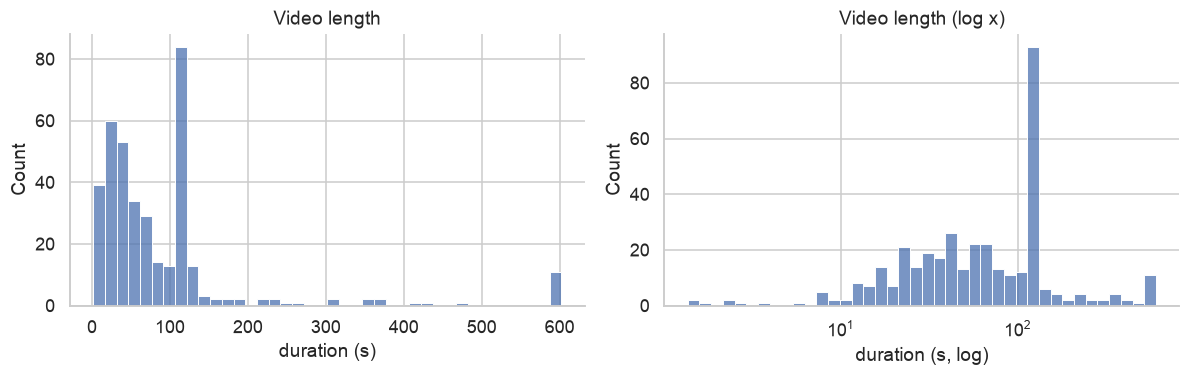

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
sns.histplot(df.duration_s, bins=40, ax=ax[0]); ax[0].set(xlabel='duration (s)', title='Video length')
sns.histplot(df.duration_s, bins=40, log_scale=True, ax=ax[1]); ax[1].set(xlabel='duration (s, log)', title='Video length (log x)')
plt.tight_layout()

## Per organ and category

In [5]:
def summarize(g):
    s = df.groupby(g).duration_s.agg(videos='count', total_min=lambda x: x.sum()/60,
                                      mean_s='mean', median_s='median', max_s='max')
    s['share_%'] = 100 * s.total_min / (df.duration_s.sum()/60)
    return s.round(1)

summarize('organ')

,videos,total_min,mean_s,median_s,max_s,share_%
organ,,,,,,
Lower GI,314,503.1,96.1,63.9,602.2,86.7
Upper GI,60,77.4,77.4,54.5,436.0,13.3


In [6]:
summarize(['organ', 'category']).sort_values('total_min', ascending=False)

videos  total_min  mean_s  median_s  \
organ    category                                                         
Lower GI Therapeutic interventions     142      312.9   132.2     120.2   
         Pathological findings         103      134.2    78.2      55.4   
Upper GI Pathological findings          43       59.2    82.6      68.3   
Lower GI Quality of mucosal views       65       53.6    49.5      24.2   
Upper GI Therapeutic interventions       4        9.8   147.3      56.6   
         Anatomical landmarks           10        6.8    40.6      34.5   
Lower GI Anatomical landmarks            4        2.4    36.4      31.8   
Upper GI Quality of mucosal views        3        1.6    32.5      26.7   

                                    max_s  share_%  
organ    category                                   
Lower GI Therapeutic interventions  602.2     53.9  
         Pathological findings      478.0     23.1  
Upper GI Pathological findings      363.8     10.2  
Lower GI Quality of mucosal views   600.2      9.2  
Upper GI Therapeutic interventions  436.0      1.7  
         Anatomical landmarks       120.2      1.2  
Lower GI Anatomical landmarks        78.4      0.4  
Upper GI Quality of mucosal views    68.4      0.3

[Text(0.5, 0, 'total video length (min)'),
 Text(0, 0.5, ''),
 Text(0.5, 1.0, 'Video length by category and organ')]

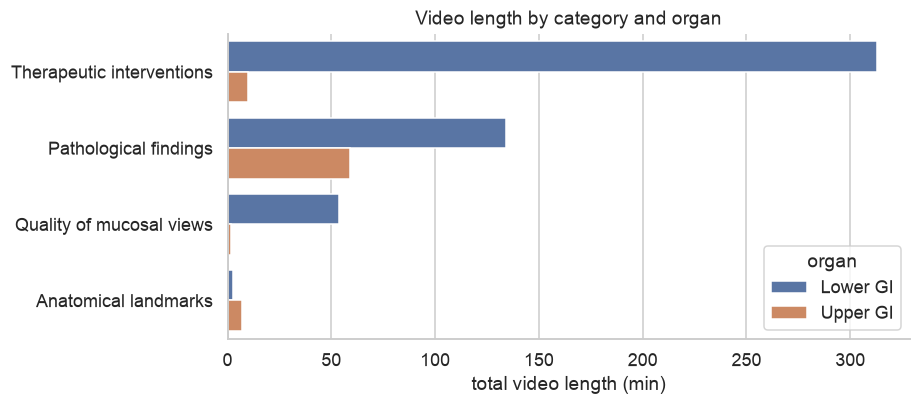

In [7]:
order = df.groupby('category').minutes.sum().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(8, 3.6))
sns.barplot(df.groupby(['category', 'organ'], as_index=False).minutes.sum(), y='category', x='minutes',
            hue='organ', order=order, ax=ax)
ax.set(xlabel='total video length (min)', ylabel='', title='Video length by category and organ')

## Per finding (the class label)

In [8]:
by_finding = (df.groupby(['organ', 'category', 'finding'])
                .duration_s.agg(videos='count', total_min=lambda x: x.sum()/60, mean_s='mean', median_s='median')
                .round(1).sort_values('total_min', ascending=False).reset_index())
by_finding

,organ,category,finding,videos,total_min,mean_s,median_s
0,Lower GI,Therapeutic interventions,dyed lifted polyps,94,222.9,142.3,120.2
1,Lower GI,Pathological findings,polyps,69,92.0,80.0,55.4
2,Lower GI,Therapeutic interventions,snare resection,13,34.7,160.2,126.0
3,Lower GI,Quality of mucosal views,bbps 2-3,31,34.6,67.0,24.7
4,Upper GI,Pathological findings,ulcer,17,27.7,97.7,120.1
5,Lower GI,Therapeutic interventions,dyed resection margins,19,23.4,73.9,67.6
6,Lower GI,Quality of mucosal views,bbps 0-1,34,19.0,33.6,24.0
7,Lower GI,Therapeutic interventions,self-expanding stent,10,17.7,106.4,120.2
8,Lower GI,Pathological findings,colitis,15,17.0,67.8,61.4
9,Lower GI,Therapeutic interventions,clip placement,6,14.1,141.2,124.6


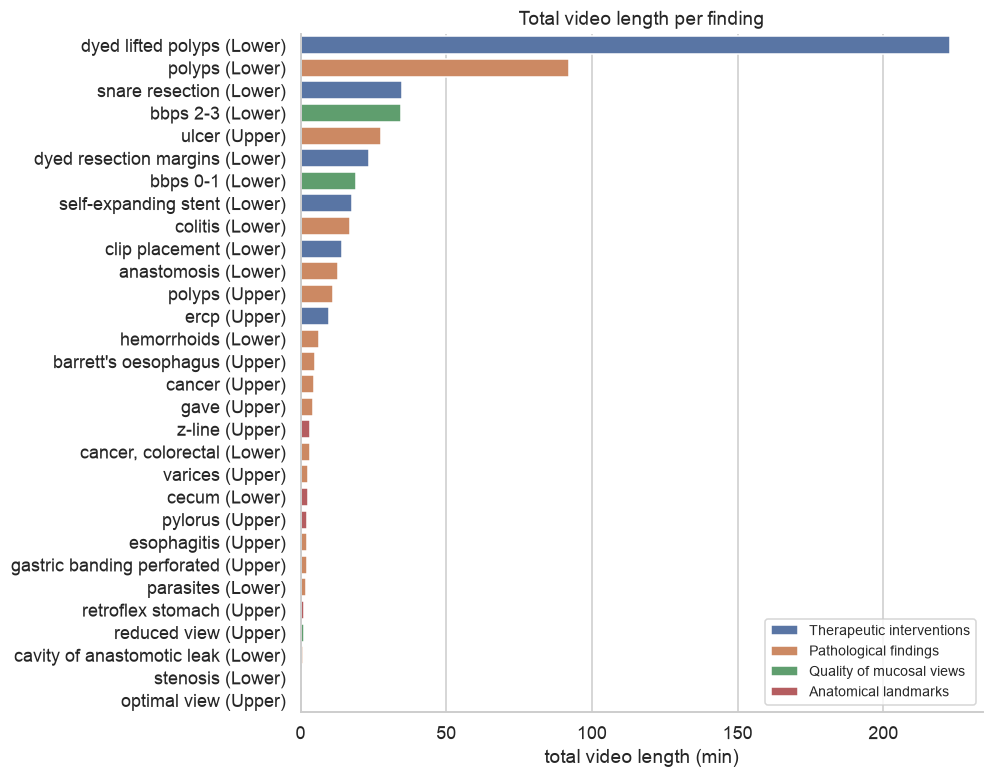

In [9]:
top = by_finding.assign(label=lambda d: d.finding + ' (' + d.organ.str[:5] + ')')
fig, ax = plt.subplots(figsize=(8, 8))
sns.barplot(top, y='label', x='total_min', hue='category', dodge=False, ax=ax)
ax.set(xlabel='total video length (min)', ylabel='', title='Total video length per finding')
ax.legend(title='', loc='lower right', fontsize=9)

[None,
 Text(0.5, 0, 'duration (s, log)'),
 Text(0, 0.5, ''),
 Text(0.5, 1.0, 'Length distribution per finding')]

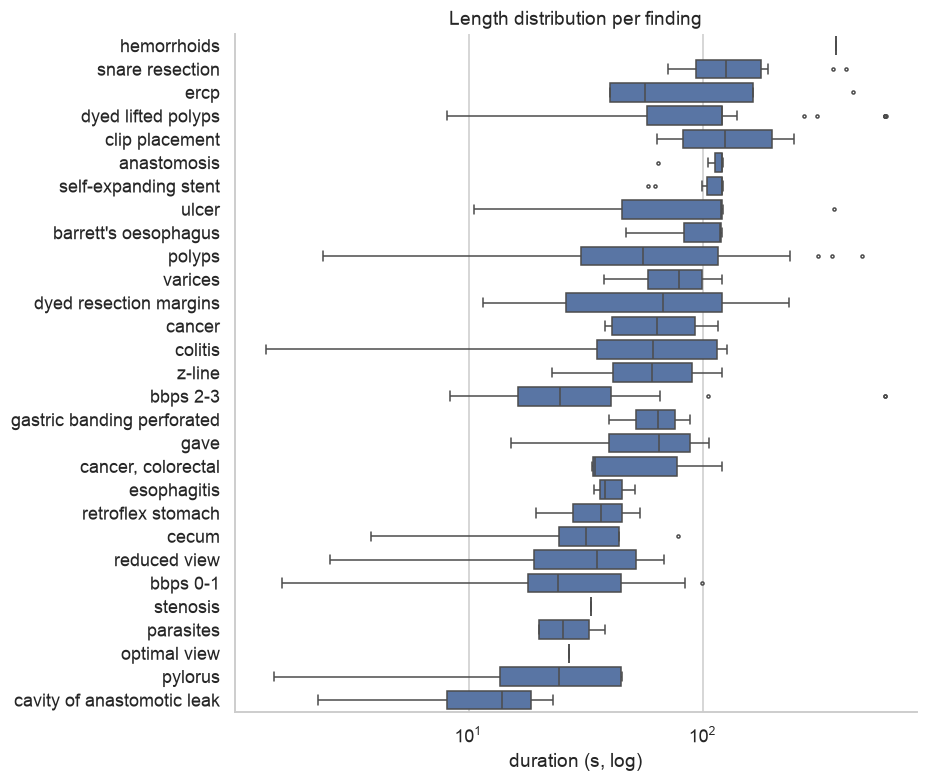

In [10]:
fig, ax = plt.subplots(figsize=(8, 8))
order = by_finding.sort_values('mean_s', ascending=False).finding
sns.boxplot(df, y='finding', x='duration_s', order=order, color='C0', fliersize=2, ax=ax)
ax.set(xscale='log', xlabel='duration (s, log)', ylabel='', title='Length distribution per finding')

### Pathology only (diseases / abnormalities)

In [11]:
path = by_finding[by_finding.category == 'Pathological findings']
print(f'{path.total_min.sum()/60:.2f} h of pathological video across {path.videos.sum()} videos')
path.drop(columns='category')

3.23 h of pathological video across 146 videos


,organ,finding,videos,total_min,mean_s,median_s
1,Lower GI,polyps,69,92.0,80.0,55.4
4,Upper GI,ulcer,17,27.7,97.7,120.1
8,Lower GI,colitis,15,17.0,67.8,61.4
10,Lower GI,anastomosis,7,12.9,110.3,120.2
11,Upper GI,polyps,8,11.0,82.7,65.0
13,Lower GI,hemorrhoids,1,6.2,370.0,370.0
14,Upper GI,barrett's oesophagus,3,4.8,95.2,118.3
15,Upper GI,cancer,4,4.7,70.3,63.8
16,Upper GI,gave,4,4.2,63.0,65.3
18,Lower GI,"cancer, colorectal",3,3.1,62.8,34.7


## Secondary labels
Some videos carry a second finding (e.g. a polyp that also shows a therapeutic intervention).

In [12]:
print(df.category2.value_counts(dropna=False).to_string())
df.groupby('finding2').minutes.agg(['count', 'sum']).round(1).sort_values('sum', ascending=False).head(15)

category2
NaN                          330
Therapeutic interventions     25
Pathological findings         10
Anatomical landmarks           8
Quality of mucosal views       1


,count,sum
finding2,,
normal mucosa,7,19.1
hemospray,2,13.3
clip placement,1,6.8
incision in colonoc anastomosis,3,6.0
heatherprobe,2,4.0
injection,2,4.0
APC,2,3.1
Normal mucosa,9,3.0
Z-line,2,2.5


## Technical properties

In [13]:
print(df.groupby(['width', 'height']).agg(videos=('id', 'count'), hours=('minutes', lambda x: x.sum()/60)).round(2).to_string())
print(df.fps.round(1).value_counts().to_string())
print(df.codec.value_counts().to_string())

              videos  hours
width height               
576   576          2   0.01
720   576        298   8.03
768   576          3   0.02
1280  1024        60   1.23
1920  1072        11   0.39
fps
25.0    350
30.0     19
20.0      3
50.0      2
codec
vc1           369
rawvideo        3
mpeg1video      2


## Consistency check: directory vs label CSV
The folder a video sits in and its CSV `Finding 1`/`Classification 1` don't always agree.

In [14]:
mism = df[df.category_dir.str.replace('-', ' ').str.lower().str.rstrip('s') != df.category.str.lower().str.rstrip('s')]
mism.groupby(['category_dir', 'folder', 'category', 'finding']).size().rename('videos')

category_dir               folder       category                   finding               
pathological-findings      polyps       Therapeutic interventions  clip placement            1
                                                                   dyed resection margins    1
                                                                   snare resection           2
therapeutic-interventions  anastomosis  Pathological findings      anastomosis               7
Name: videos, dtype: int64